# Phase 2 & 4: Segmentation (U-Net)

A U-Net with a pretrained ResNet34 encoder draws the outline (mask) of every lesion.

One setting, `MULTI_TASK`, switches between the two phases:

| `MULTI_TASK` | Phase | Model outputs | Saved to |
| :----------: | ----- | ------------- | -------- |
| `False` | Phase 2 | Lesion mask | `outputs/unet/` |
| `True` | Phase 4 | Lesion mask **and** normal / benign / malignant | `outputs/unet_multitask/` |

Run it once with each setting to compare them. Each run saves to its own folder.

**Input:** `data/manifest.csv` (created by `00_clean_data.ipynb`)

**Output** (everything the Streamlit app needs):

| File | What it contains |
| ---- | ---------------- |
| `model.pt` | Trained model weights (best epoch) |
| `config.json` | Architecture, image size, normalisation, **thresholds, mask smoothing and cleanup** and training settings |
| `history.csv` | Loss, Dice and accuracy for every epoch |
| `metrics.json` | Test results (v2), with 95% confidence ranges |
| `metrics_v1_vs_v2.csv` | v1 and v2 test results side by side |
| `test_predictions.csv` | Dice, IoU and lesion area (v1 and v2) for every test image (+ class probabilities and predictions if multi-task) |
| `masks/` | Predicted mask (v2) for every test image, at the original image size (used by `04_measure`) |
| `threshold_tuning.png` | Malignant threshold and normal-gate tuning on the validation set |
| `training_curves.png`, `dice_distribution.png`, `prediction_examples.png`, `worst_predictions.png` | Result plots |
| `confusion_matrix.png` | Test confusion matrices, v1 and v2 (multi-task only) |

**Before the first run:** install the U-Net library with `.env/bin/pip install segmentation-models-pytorch`. The pretrained encoder weights download automatically the first time (about 85 MB).

---

### v2 changes

| Change | Why | Kept? |
| ------ | --- | :---: |
| `TRAIN` setting: `False` reuses the trained v1 model | Fixes are measured on the **same model**, so any change in the scores comes from the fix, not from training randomness | ✅ |
| **Malignant threshold tuned on the validation set** (same method as `02`) | v1 caught only 21 of 30 cancers (70%) even though the malignant ROC-AUC was 0.97 | ✅ (came out at 0.50, so no change for this model) |
| **Smooth masks:** enlarge the probability map to the original size first, then threshold | v1 thresholded at 256 x 256 and then enlarged the yes/no mask, giving staircase edges: predicted outlines looked rougher and less round than the real lesions, which skewed the shape results | ✅ |
| **Mask cleanup:** fill holes, drop regions smaller than `MIN_REGION_PCT` % of the image | v1 produced 29 false lesions, many of them small fragments | ✅ |
| **Normal gate:** if the classification head is confident the scan is normal, the mask is discarded | v1 drew a lesion on 18% of normal scans | ❌ tested, switched off (see section 7) |
| **95% confidence ranges** (bootstrap) and v1 vs v2 side by side | The test set is small, so we need to see how much of a change is luck | ✅ |

The v1 results are archived in `outputs/archive/v1_baseline/` and git tag `v1-baseline`.

## 1. Imports

In [70]:
import json
import random
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import segmentation_models_pytorch as smp
from PIL import Image, ImageOps
from scipy import ndimage                     # v2: hole filling and region sizes for mask cleanup
from torch.utils.data import Dataset, DataLoader
from torchvision import tv_tensors
from torchvision.transforms import v2
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score

## 2. Settings

In [71]:
DATA_DIR = Path('data')

MULTI_TASK = True    # False = Phase 2 (mask only), True = Phase 4 (mask + normal / benign / malignant)

OUTPUT_DIR = Path('outputs/unet_multitask' if MULTI_TASK else 'outputs/unet')
MASK_DIR = OUTPUT_DIR / 'masks'                 # predicted test masks go here
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASSES = ['normal', 'benign', 'malignant']     # class numbers 0, 1, 2
ENCODER = 'resnet34'          # pretrained backbone of the U-Net
IMAGE_SIZE = 256              # every scan is padded and resized to 256 x 256
BATCH_SIZE = 8
EPOCHS = 40                   # maximum; training can stop earlier
LEARNING_RATE = 1e-4
PATIENCE = 8                  # stop if validation loss hasn't improved for this many epochs
CLASS_LOSS_WEIGHT = 0.5       # how much the classification loss counts compared to the mask loss
MASK_THRESHOLD = 0.5          # pixels with lesion probability above this are part of the mask
MIN_LESION_PIXELS = 50        # same as 00_clean_data: smaller regions are noise
RANDOM_STATE = 42

TRAIN = False                   # v2: False = reuse the saved model.pt, True = train a new model
TARGET_MALIGNANT_RECALL = 0.90  # v2: the malignant threshold is tuned to reach this recall on the validation set
SMOOTH_MASKS = True             # v2: enlarge the probability map to full size before thresholding (smooth edges)
CLEAN_MASKS = True              # v2: fill holes and drop small regions in predicted masks
MIN_REGION_PCT = 0.2            # v2: regions smaller than this % of the image are dropped (smallest real lesion is ~0.3%)
NORMAL_GATE = False             # v2: off - in testing it removed a real lesion and none of the false ones (see section 7)
N_BOOTSTRAP = 1000              # v2: resamples used for the 95% confidence ranges

IMAGENET_MEAN = [0.485, 0.456, 0.406]           # the pretrained encoder expects images normalised this way
IMAGENET_STD = [0.229, 0.224, 0.225]

# Same results every run
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

# Use the Apple GPU (mps) if available, otherwise the CPU
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print('Using device:', device, '| Multi-task:', MULTI_TASK, '| Train a new model:', TRAIN, '| Saving to:', OUTPUT_DIR)

Using device: mps | Multi-task: True | Train a new model: False | Saving to: outputs/unet_multitask


## 3. Load the manifest

In [72]:
df = pd.read_csv(DATA_DIR / 'manifest.csv')
df['target'] = df['label'].map(CLASSES.index)     # class name -> class number

train_df = df[df['split'] == 'train'].reset_index(drop=True)
val_df = df[df['split'] == 'val'].reset_index(drop=True)
test_df = df[df['split'] == 'test'].reset_index(drop=True)

print(f'Train: {len(train_df)}  |  Val: {len(val_df)}  |  Test: {len(test_df)}')

Train: 485  |  Val: 104  |  Test: 104


## 4. Images, masks and helper functions

Image and mask go through the **same** padding and resizing, so they stay perfectly aligned:
- **Image:** grayscale, then black borders to make it square, then resize to 256 x 256 (smooth resizing).
- **Mask:** all of the image's masks merged into one, then the same borders and resize, using *nearest-neighbour* resizing so pixels stay exactly 0 or 1.

Going back to the original image size, so lesions can be measured in real image pixels:
- `unpad_mask` (v1): cuts the borders off a predicted **yes/no** mask and enlarges it. Enlarging a yes/no mask about 2x gives staircase edges.
- `unpad_probs` (**v2**): cuts the borders off the predicted **probability map** and enlarges it smoothly (bilinear). Thresholding afterwards gives smooth edges.

In [73]:
def pad_to_square(image, is_mask=False, size=IMAGE_SIZE):
    """Fit an image into size x size with black borders (no stretching)."""
    method = Image.NEAREST if is_mask else Image.BICUBIC      # nearest keeps mask pixels exactly 0 or 255
    return ImageOps.pad(image, (size, size), method=method, color=0)


def load_mask(mask_paths):
    """Merge all masks of an image into one PIL image (255 = lesion, 0 = background)."""
    masks = [np.array(Image.open(DATA_DIR / p).convert('L')) > 127 for p in mask_paths.split(';')]
    return Image.fromarray(np.any(masks, axis=0).astype(np.uint8) * 255)


def crop_box(width, height, size=IMAGE_SIZE):
    """Where the original image sits inside the padded square: (left, top, new_width, new_height)."""
    scale = size / max(width, height)
    new_width, new_height = round(width * scale), round(height * scale)              # image size inside the square
    left, top = round((size - new_width) / 2), round((size - new_height) / 2)        # where the image starts
    return left, top, new_width, new_height


def unpad_mask(mask, width, height, size=IMAGE_SIZE):
    """Undo pad_to_square: cut off the borders and resize a True/False mask back to width x height (v1 method)."""
    left, top, new_width, new_height = crop_box(width, height, size)
    cropped = mask[top:top + new_height, left:left + new_width]
    resized = Image.fromarray(cropped.astype(np.uint8) * 255).resize((width, height), Image.NEAREST)
    return np.array(resized) > 127


def unpad_probs(probs, width, height, size=IMAGE_SIZE):
    """v2: undo pad_to_square for a probability map: cut off the borders and resize smoothly back to width x height.
    Threshold the result afterwards to get a mask with smooth edges."""
    left, top, new_width, new_height = crop_box(width, height, size)
    cropped = probs[top:top + new_height, left:left + new_width].astype(np.float32)
    return np.array(Image.fromarray(cropped).resize((width, height), Image.BILINEAR))


def dice_score(pred, truth):
    """Overlap of two True/False masks: 1 = identical, 0 = no overlap."""
    total = pred.sum() + truth.sum()
    return 1.0 if total == 0 else float(2 * (pred & truth).sum() / total)


def iou_score(pred, truth):
    """Intersection over union of two True/False masks: 1 = identical, 0 = no overlap."""
    union = (pred | truth).sum()
    return 1.0 if union == 0 else float((pred & truth).sum() / union)

In [74]:
# Check: padding a real mask and undoing it should give back (almost) the same mask
row = df[df['label'] == 'malignant'].iloc[0]
original = np.array(load_mask(row['mask_paths'])) > 127
padded = np.array(pad_to_square(load_mask(row['mask_paths']), is_mask=True)) > 127
round_trip = unpad_mask(padded, row['width'], row['height'])

print(f'Dice after pad + unpad: {dice_score(round_trip, original):.3f}  (should be close to 1; '
      f'a little below is normal because the mask was shrunk to 256 x 256)')

Dice after pad + unpad: 0.996  (should be close to 1; a little below is normal because the mask was shrunk to 256 x 256)


### Augmentation and dataset

Training images get small random flips, rotations, shifts and zooms. Each change is applied to the image **and** its mask together, so the outline still matches. Brightness and contrast changes only affect the image. There are no vertical flips, because the skin is always at the top.

In [75]:
train_augment = v2.Compose([
    v2.RandomHorizontalFlip(),                                              # left-right flip only
    v2.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),  # small rotation, shift, zoom
    v2.ColorJitter(brightness=0.2, contrast=0.2),                           # image only, the mask is untouched
])

MEAN = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
STD = torch.tensor(IMAGENET_STD).view(3, 1, 1)


def to_model_input(image):
    """1-channel uint8 image tensor (1, H, W) -> normalised 3-channel float tensor (3, H, W)."""
    x = torch.as_tensor(image).float().div(255).repeat(3, 1, 1)   # 0..255 -> 0..1, then copy to 3 channels
    return (x - MEAN) / STD


class ScanMaskDataset(Dataset):
    """Gives (image tensor, mask tensor, class number) for each row of the manifest."""

    def __init__(self, frame, augment=None):
        self.frame = frame
        self.augment = augment

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, i):
        row = self.frame.iloc[i]
        image = pad_to_square(Image.open(DATA_DIR / row['image_path']).convert('L'))
        mask = pad_to_square(load_mask(row['mask_paths']), is_mask=True)

        image = tv_tensors.Image(torch.from_numpy(np.array(image)).unsqueeze(0))                   # (1, H, W)
        mask = tv_tensors.Mask(torch.from_numpy(np.array(mask) > 127).unsqueeze(0).to(torch.uint8))
        if self.augment:
            image, mask = self.augment(image, mask)       # same random change for image and mask

        return to_model_input(image), torch.as_tensor(mask).float(), row['target']


train_loader = DataLoader(ScanMaskDataset(train_df, train_augment), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(ScanMaskDataset(val_df), batch_size=BATCH_SIZE)
test_loader = DataLoader(ScanMaskDataset(test_df), batch_size=BATCH_SIZE)    # keeps test_df order

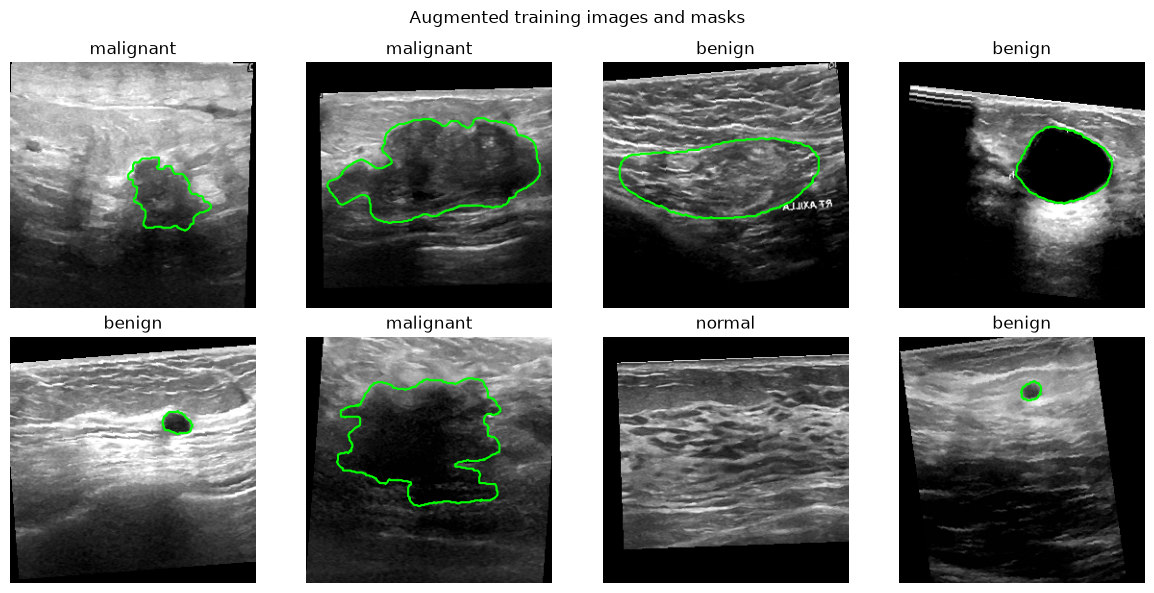

In [76]:
# Look at one batch of augmented training images with their masks (green outline)
images, masks, targets = next(iter(train_loader))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, image, mask, target in zip(axes.flat, images, masks, targets):
    ax.imshow((image[0] * IMAGENET_STD[0] + IMAGENET_MEAN[0]).numpy(), cmap='gray')   # undo normalisation
    if mask.any():
        ax.contour(mask[0].numpy(), levels=[0.5], colors='lime', linewidths=1.5)
    ax.set_title(CLASSES[target])
    ax.axis('off')
plt.suptitle('Augmented training images and masks')
plt.tight_layout()
plt.show()

## 5. Model and loss

**U-Net:** the *encoder* (a ResNet34 pretrained on ImageNet) shrinks the image step by step into features. The *decoder* grows those features back to full size to draw the mask. *Skip connections* pass details from each encoder step to the decoder, which keeps the edges sharp.

With `MULTI_TASK = True`, a small **classification head** also reads the encoder's deepest features and predicts normal / benign / malignant.

**Mask loss = Dice loss + binary cross-entropy:**
- **Dice loss** rewards overlap between the predicted and true mask. It works well even when the lesion is a small part of the image.
- **Binary cross-entropy** checks every pixel and keeps training stable.

**Classification loss:** weighted cross-entropy, the same as in `02_model_classifier`.

`total loss = mask loss + CLASS_LOSS_WEIGHT x classification loss`

In [77]:
model = smp.Unet(
    encoder_name=ENCODER,                # ResNet34 backbone
    encoder_weights='imagenet',          # start from ImageNet weights
    in_channels=3,
    classes=1,                           # one output channel: lesion vs background
    aux_params={'classes': len(CLASSES), 'dropout': 0.2} if MULTI_TASK else None,   # classification head
).to(device)


def forward(images):
    """Run the model. Always returns (mask_logits, class_logits); class_logits is None without multi-task."""
    output = model(images)
    return output if MULTI_TASK else (output, None)

In [78]:
def dice_loss(mask_logits, masks, smooth=1.0):
    """1 - Dice overlap between predicted probabilities and true masks (0 = perfect)."""
    probs = torch.sigmoid(mask_logits)
    intersection = (probs * masks).sum()
    return 1 - (2 * intersection + smooth) / (probs.sum() + masks.sum() + smooth)


bce_loss = nn.BCEWithLogitsLoss()

counts = train_df['target'].value_counts().sort_index()                            # images per class (train)
class_weights = torch.tensor(len(train_df) / (len(CLASSES) * counts.values), dtype=torch.float32)
class_loss_fn = nn.CrossEntropyLoss(weight=class_weights.to(device))


def total_loss(mask_logits, class_logits, masks, targets):
    """Mask loss, plus the weighted classification loss when multi-task."""
    loss = dice_loss(mask_logits, masks) + bce_loss(mask_logits, masks)
    if MULTI_TASK:
        loss = loss + CLASS_LOSS_WEIGHT * class_loss_fn(class_logits, targets)
    return loss


optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

## 6. Train

Every epoch we track the loss, the **Dice score** (mask overlap over the whole set, 1 = perfect) and, for multi-task, the classification accuracy. The model with the lowest validation loss is saved to `model.pt`, and training stops early if it hasn't improved for `PATIENCE` epochs.

**v2:** with `TRAIN = False`, training is skipped and the saved `model.pt` and `history.csv` from the previous run are reused.

In [79]:
def run_epoch(loader, train):
    """One pass over the data. Updates the weights only when train=True. Returns (loss, dice, accuracy)."""
    model.train(train)
    total, overlap, mask_total, correct = 0.0, 0.0, 0.0, 0

    for images, masks, targets in loader:
        images, masks, targets = images.to(device), masks.to(device), targets.to(device)

        with torch.set_grad_enabled(train):                 # only track gradients when training
            mask_logits, class_logits = forward(images)
            loss = total_loss(mask_logits, class_logits, masks, targets)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

        with torch.no_grad():                               # scores for this batch
            total += loss.item() * len(targets)
            predicted = (torch.sigmoid(mask_logits) > MASK_THRESHOLD).float()
            overlap += (predicted * masks).sum().item()
            mask_total += (predicted.sum() + masks.sum()).item()
            if MULTI_TASK:
                correct += (class_logits.argmax(dim=1) == targets).sum().item()

    n = len(loader.dataset)
    return total / n, 2 * overlap / max(mask_total, 1), correct / n

In [80]:
if TRAIN:
    history = []
    best_val_loss, best_epoch, epochs_without_improvement = float('inf'), 0, 0

    for epoch in range(1, EPOCHS + 1):
        train_loss, train_dice, train_acc = run_epoch(train_loader, train=True)
        val_loss, val_dice, val_acc = run_epoch(val_loader, train=False)
        history.append({'epoch': epoch, 'train_loss': train_loss, 'train_dice': train_dice, 'train_acc': train_acc,
                        'val_loss': val_loss, 'val_dice': val_dice, 'val_acc': val_acc})

        message = f'Epoch {epoch:2d} | train loss {train_loss:.4f}  dice {train_dice:.3f} | val loss {val_loss:.4f}  dice {val_dice:.3f}'
        if MULTI_TASK:
            message += f'  acc {val_acc:.3f}'
        print(message)

        if val_loss < best_val_loss:                         # new best: save this model
            best_val_loss, best_epoch, epochs_without_improvement = val_loss, epoch, 0
            torch.save(model.state_dict(), OUTPUT_DIR / 'model.pt')
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= PATIENCE:
                print(f'Stopping early: no improvement for {PATIENCE} epochs')
                break

    print(f'Best model: epoch {best_epoch} (val loss {best_val_loss:.4f}), saved to {OUTPUT_DIR}/model.pt')
    history = pd.DataFrame(history)
    history.to_csv(OUTPUT_DIR / 'history.csv', index=False)
else:
    # v2: reuse the previous run's model, history and settings (nothing is retrained)
    previous_config = json.loads((OUTPUT_DIR / 'config.json').read_text())
    history = pd.read_csv(OUTPUT_DIR / 'history.csv')
    best_epoch = previous_config['best_epoch']
    print(f'Skipping training: reusing {OUTPUT_DIR}/model.pt (best epoch {best_epoch}, '
          f"trained on {previous_config['trained_on']})")

Skipping training: reusing outputs/unet_multitask/model.pt (best epoch 23, trained on 2026-11-10 23:22)


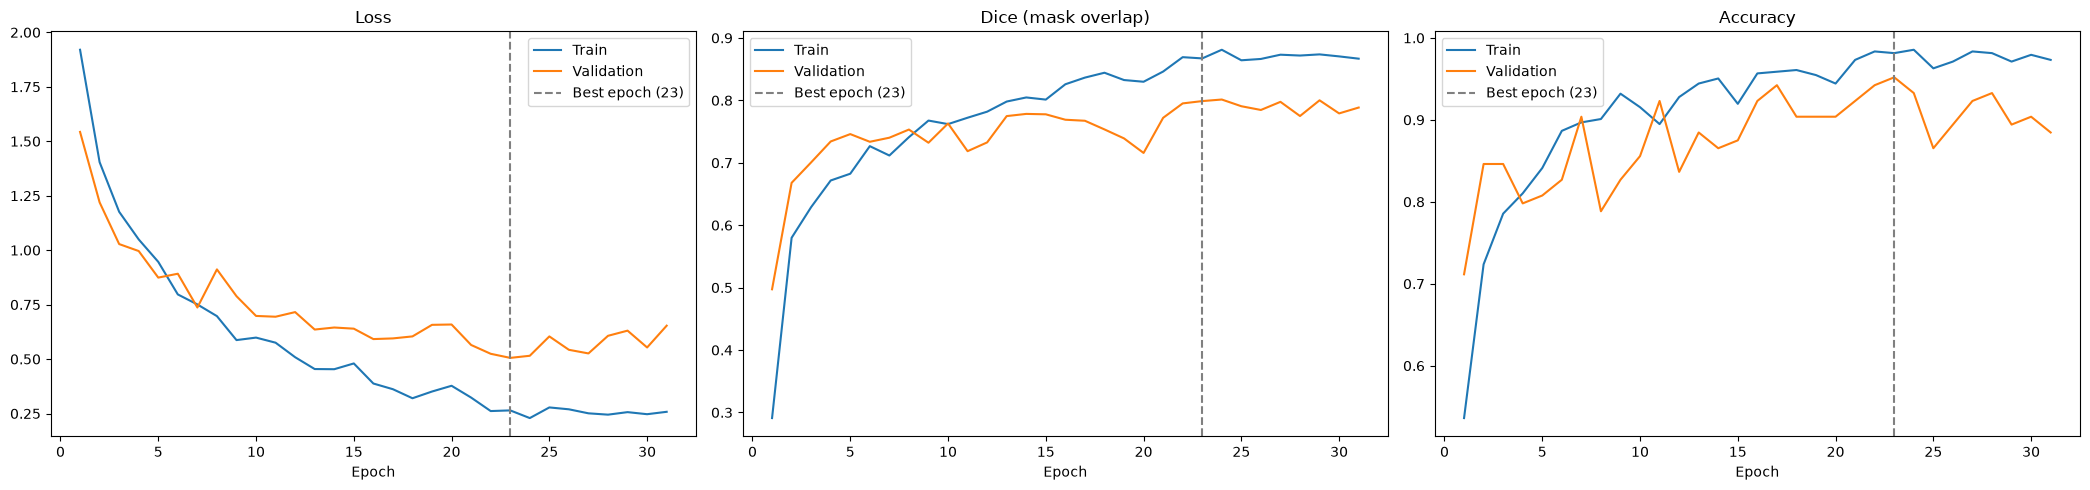

In [81]:
plots = [('loss', 'Loss'), ('dice', 'Dice (mask overlap)')] + ([('acc', 'Accuracy')] if MULTI_TASK else [])
fig, axes = plt.subplots(1, len(plots), figsize=(7 * len(plots), 5))

for ax, (metric, title) in zip(axes, plots):
    ax.plot(history['epoch'], history[f'train_{metric}'], label='Train')
    ax.plot(history['epoch'], history[f'val_{metric}'], label='Validation')
    ax.axvline(best_epoch, color='grey', linestyle='--', label=f'Best epoch ({best_epoch})')
    ax.set_xlabel('Epoch')
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'training_curves.png', dpi=120, bbox_inches='tight')
plt.show()

## 7. Evaluate on the test set

We reload the **best** saved model and predict every validation and test image.

**From model output to final mask and class:**

| Step | v1 | v2 |
| ---- | -- | -- |
| 1. Mask | Threshold at 256 x 256, then enlarge the yes/no mask to the original size | **Enlarge the probability map smoothly to the original size, then threshold** (`SMOOTH_MASKS`) |
| 2. Cleanup | None | Fill holes; drop regions smaller than `MIN_REGION_PCT` % of the image (`CLEAN_MASKS`) |
| 3. Class | Most likely class | Malignant if P(malignant) ≥ tuned threshold, otherwise the more likely of normal / benign |
| 4. Normal gate | None | Tested and **switched off** (`NORMAL_GATE = False`); see the findings below |

Thresholds are tuned on the **validation set only**. The test set is used once, for the final results. The v2 masks are saved to `masks/` for `04_measure`.

In [82]:
model.load_state_dict(torch.load(OUTPUT_DIR / 'model.pt', map_location=device))
model.eval()


def predict_set(loader):
    """Lesion probability maps (N, 256, 256) and class probabilities (N, 3), or None without multi-task."""
    mask_probs, class_probs = [], []
    with torch.no_grad():
        for images, _, _ in loader:
            mask_logits, class_logits = forward(images.to(device))
            mask_probs.append(torch.sigmoid(mask_logits)[:, 0].cpu())          # lesion probability per pixel
            if MULTI_TASK:
                class_probs.append(torch.softmax(class_logits, dim=1).cpu())   # [P(normal), P(benign), P(malignant)]
    return torch.cat(mask_probs).numpy(), (torch.cat(class_probs).numpy() if MULTI_TASK else None)


def decide(probs, malignant_threshold=None):
    """Turn class probabilities into class numbers.
    v1 (no threshold): the most likely class.
    v2 (threshold): malignant if P(malignant) >= threshold, otherwise the more likely of normal / benign."""
    if malignant_threshold is None:
        return probs.argmax(axis=1)
    return np.where(probs[:, 2] >= malignant_threshold, 2, probs[:, :2].argmax(axis=1))


def clean_mask(mask, min_region_pct=MIN_REGION_PCT, min_pixels=MIN_LESION_PIXELS):
    """v2: fill holes inside lesions, then drop regions smaller than min_region_pct % of the image."""
    filled = ndimage.binary_fill_holes(mask)
    labelled, n_regions = ndimage.label(filled, structure=np.ones((3, 3)))     # number each separate region
    sizes = ndimage.sum(filled, labelled, range(1, n_regions + 1))             # pixels in each region
    min_size = max(min_pixels, mask.size * min_region_pct / 100)
    keep = [number for number, size in enumerate(sizes, start=1) if size >= min_size]
    return np.isin(labelled, keep)


val_mask_probs, val_class_probs = predict_set(val_loader)     # v2: used only for tuning
mask_probs, class_probs = predict_set(test_loader)            # used only for the final test results

### v2: tune on the validation set

1. **Smoothing and cleanup:** first we check how much they change false lesions and missed tumours on the validation set.
2. **Malignant threshold** (multi-task only): the highest threshold that still catches `TARGET_MALIGNANT_RECALL` of the validation cancers, the same method as `02_model_classifier`.
3. **Normal gate** (multi-task only, if switched on): for each P(normal) level from 0.50 to 0.99, we count false lesions on normal scans and tumour scans left with no lesion, and pick the **lowest** level that doesn't leave any extra tumour scan without a lesion.

**v2 findings:**
- **Malignant threshold:** came out at 0.50, so no change. The validation set already showed 93.5% malignant recall, but the test set shows 70%. The validation set was also used to choose the best epoch, so it flatters this model, and thresholds tuned on it don't carry over to the test set.
- **Normal gate (level 0.65):** switched **off** (`NORMAL_GATE = False`). The false lesions on normal test scans were all confidently classified as benign (P(normal) 0.04–0.23), so the gate never applied to them. It removed one real lesion instead (`benign (316)`, P(normal) 0.98, mask Dice 0.67).
- **Mask cleanup:** kept. It removed 6 false lesions (29 → 23) without losing any real ones, filled holes in some outlines (e.g. Dice 0.897 → 0.946), and removed one meaningless fragment (204 px, Dice 0.01).
- **Smooth masks:** added after checking `04_measure`. Predicted benign outlines were rougher (median edge roughness 1.109 vs 1.008) and less round (circularity 0.654 vs 0.812) than the real lesions, because the yes/no mask was enlarged about 2x.

Validation (v1 masks): false lesion on 5.9% of normal scans, no lesion found on 2.3% of tumour scans
Validation (v2 masks): false lesion on 5.9% of normal scans, no lesion found on 2.3% of tumour scans
Malignant threshold: 0.50  (validation recall 0.935, precision 0.906)
Normal gate off


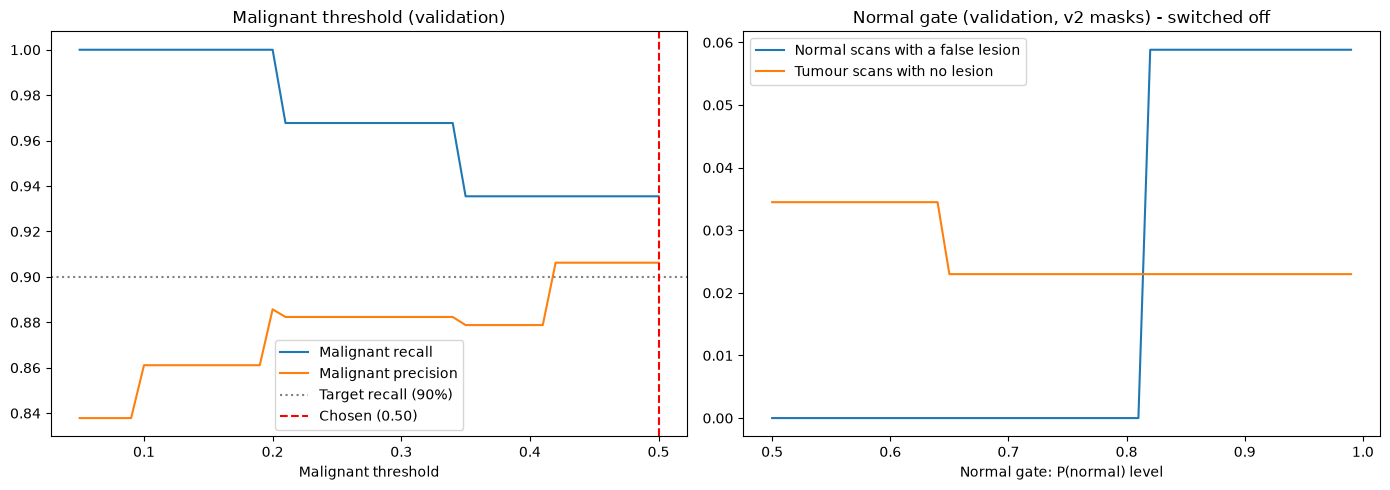

In [83]:
# v2: validation masks at the original image size: v1 (raw) and v2 (smoothed + cleaned)
def final_mask(probs, width, height):
    """v2 mask at the original size: smooth enlargement (if SMOOTH_MASKS), threshold, then cleanup (if CLEAN_MASKS)."""
    if SMOOTH_MASKS:
        mask = unpad_probs(probs, width, height) > MASK_THRESHOLD
    else:
        mask = unpad_mask(probs > MASK_THRESHOLD, width, height)
    return clean_mask(mask) if CLEAN_MASKS else mask


val_rows = []
for i, row in val_df.iterrows():
    raw = unpad_mask(val_mask_probs[i] > MASK_THRESHOLD, row['width'], row['height'])   # v1
    final = final_mask(val_mask_probs[i], row['width'], row['height'])                   # v2
    val_rows.append({'label': row['label'], 'raw_area': int(raw.sum()), 'clean_area': int(final.sum())})
val_masks = pd.DataFrame(val_rows)
val_tumour = (val_masks['label'] != 'normal').values

for column, name in [('raw_area', 'v1'), ('clean_area', 'v2')]:
    has_lesion = val_masks[column].values >= MIN_LESION_PIXELS
    print(f'Validation ({name} masks): false lesion on {has_lesion[~val_tumour].mean():.1%} of normal scans, '
          f'no lesion found on {(~has_lesion[val_tumour]).mean():.1%} of tumour scans')

MALIGNANT_THRESHOLD, NORMAL_GATE_THRESHOLD = None, None
if MULTI_TASK:
    # 1. Malignant threshold: highest threshold that still reaches the target recall (same method as 02)
    y_val_true = val_df['target'].values
    val_is_malignant = y_val_true == 2
    rows = []
    for threshold in np.round(np.arange(0.05, 0.51, 0.01), 2):
        pred = decide(val_class_probs, threshold)
        caught = ((pred == 2) & val_is_malignant).sum()
        rows.append({'threshold': threshold, 'recall': caught / val_is_malignant.sum(),
                     'precision': caught / max((pred == 2).sum(), 1)})
    tuning = pd.DataFrame(rows)
    meets_target = tuning[tuning['recall'] >= TARGET_MALIGNANT_RECALL]
    if len(meets_target):
        MALIGNANT_THRESHOLD = float(meets_target['threshold'].max())
    else:
        MALIGNANT_THRESHOLD = float(tuning.loc[tuning['recall'].idxmax(), 'threshold'])
        print(f'Target recall {TARGET_MALIGNANT_RECALL:.0%} not reached on validation: using the threshold with the best recall')
    chosen = tuning[tuning['threshold'] == MALIGNANT_THRESHOLD].iloc[0]
    print(f"Malignant threshold: {MALIGNANT_THRESHOLD:.2f}  (validation recall {chosen['recall']:.3f}, "
          f"precision {chosen['precision']:.3f})")

    # 2. Normal gate: lowest P(normal) level that doesn't take the mask away from any extra tumour scan
    val_pred = decide(val_class_probs, MALIGNANT_THRESHOLD)
    has_lesion = val_masks['clean_area'].values >= MIN_LESION_PIXELS
    missed_without_gate = (~has_lesion[val_tumour]).mean()
    rows = []
    for level in np.round(np.arange(0.50, 1.00, 0.01), 2):
        gated = (val_pred == 0) & (val_class_probs[:, 0] >= level)      # confident 'normal' -> discard the mask
        lesion = has_lesion & ~gated
        rows.append({'level': level, 'false_lesion_normal': lesion[~val_tumour].mean(),
                     'tumour_missed': (~lesion[val_tumour]).mean()})
    gate_tuning = pd.DataFrame(rows)
    safe = gate_tuning[gate_tuning['tumour_missed'] <= missed_without_gate + 1e-9]
    if NORMAL_GATE and len(safe):
        NORMAL_GATE_THRESHOLD = float(safe['level'].min())
        chosen = safe[safe['level'] == NORMAL_GATE_THRESHOLD].iloc[0]
        print(f"Normal gate: discard the mask when the class is normal and P(normal) >= {NORMAL_GATE_THRESHOLD:.2f}  "
              f"(validation false lesions on normal scans {chosen['false_lesion_normal']:.1%}, "
              f"tumours missed {chosen['tumour_missed']:.1%})")
    else:
        print('Normal gate off')

    # Plot both tunings
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(tuning['threshold'], tuning['recall'], label='Malignant recall')
    axes[0].plot(tuning['threshold'], tuning['precision'], label='Malignant precision')
    axes[0].axhline(TARGET_MALIGNANT_RECALL, color='grey', linestyle=':', label=f'Target recall ({TARGET_MALIGNANT_RECALL:.0%})')
    axes[0].axvline(MALIGNANT_THRESHOLD, color='red', linestyle='--', label=f'Chosen ({MALIGNANT_THRESHOLD:.2f})')
    axes[0].set_xlabel('Malignant threshold')
    axes[0].set_title('Malignant threshold (validation)')
    axes[0].legend()

    axes[1].plot(gate_tuning['level'], gate_tuning['false_lesion_normal'], label='Normal scans with a false lesion')
    axes[1].plot(gate_tuning['level'], gate_tuning['tumour_missed'], label='Tumour scans with no lesion')
    if NORMAL_GATE_THRESHOLD is not None:
        axes[1].axvline(NORMAL_GATE_THRESHOLD, color='red', linestyle='--', label=f'Chosen ({NORMAL_GATE_THRESHOLD:.2f})')
    axes[1].set_xlabel('Normal gate: P(normal) level')
    axes[1].set_title('Normal gate (validation, v2 masks)' + ('' if NORMAL_GATE else ' - switched off'))
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'threshold_tuning.png', dpi=120, bbox_inches='tight')
    plt.show()

In [84]:
if MULTI_TASK:
    y_pred_v1 = decide(class_probs)                        # v1: most likely class
    y_pred = decide(class_probs, MALIGNANT_THRESHOLD)      # v2: tuned malignant threshold

rows = []
for i, row in test_df.iterrows():
    truth = np.array(load_mask(row['mask_paths'])) > 127
    raw = unpad_mask(mask_probs[i] > MASK_THRESHOLD, row['width'], row['height'])   # v1: mask as predicted
    pred = final_mask(mask_probs[i], row['width'], row['height'])                    # v2: smoothed + cleaned
    if NORMAL_GATE_THRESHOLD is not None and y_pred[i] == 0 and class_probs[i, 0] >= NORMAL_GATE_THRESHOLD:
        pred = np.zeros_like(pred)                                                   # v2: confident 'normal' -> no lesion

    mask_path = MASK_DIR / row['image_path']                     # e.g. masks/benign/benign (12).png
    mask_path.parent.mkdir(parents=True, exist_ok=True)
    Image.fromarray(pred.astype(np.uint8) * 255).save(mask_path)  # v2 mask, used by 04_measure

    rows.append({
        'image_path': row['image_path'],
        'label': row['label'],
        'target': row['target'],
        'has_markers': row['has_markers'],
        'pred_mask_path': str(mask_path.relative_to(OUTPUT_DIR)),
        'dice_v1': dice_score(raw, truth),          # v2: keep the v1 scores for comparison
        'iou_v1': iou_score(raw, truth),
        'pred_area_px_v1': int(raw.sum()),
        'dice': dice_score(pred, truth),
        'iou': iou_score(pred, truth),
        'true_area_px': int(truth.sum()),
        'pred_area_px': int(pred.sum()),
    })

results = pd.DataFrame(rows)

if MULTI_TASK:
    for k, class_name in enumerate(CLASSES):
        results[f'prob_{class_name}'] = class_probs[:, k]      # v2: not rounded, so scores match v1 exactly
    results['predicted_v1'] = [CLASSES[k] for k in y_pred_v1]
    results['predicted'] = [CLASSES[k] for k in y_pred]
    results['correct'] = results['predicted'] == results['label']

results.to_csv(OUTPUT_DIR / 'test_predictions.csv', index=False)
print(f'Saved {len(results)} predicted masks to {MASK_DIR}')
results.head()

Saved 104 predicted masks to outputs/unet_multitask/masks


,image_path,label,target,has_markers,pred_mask_path,dice_v1,iou_v1,pred_area_px_v1,dice,iou,true_area_px,pred_area_px,prob_normal,prob_benign,prob_malignant,predicted_v1,predicted,correct
0,normal/normal (103).png,normal,0,False,masks/normal/normal (103).png,1.0,1.0,0,1.0,1.0,0,0,0.999879,0.000121,3.696497e-08,normal,normal,True
1,normal/normal (108).png,normal,0,True,masks/normal/normal (108).png,0.0,0.0,2817,0.0,0.0,0,2811,0.231351,0.747479,2.116979e-02,benign,benign,False
2,normal/normal (114).png,normal,0,True,masks/normal/normal (114).png,1.0,1.0,0,1.0,1.0,0,0,0.995923,0.004037,3.999385e-05,normal,normal,True
3,normal/normal (115).png,normal,0,False,masks/normal/normal (115).png,1.0,1.0,0,1.0,1.0,0,0,0.999929,0.000071,9.105689e-09,normal,normal,True
4,normal/normal (120).png,normal,0,False,masks/normal/normal (120).png,1.0,1.0,0,1.0,1.0,0,0,0.999744,0.000256,3.452541e-08,normal,normal,True


### Segmentation results

- **Dice and IoU** are averaged over **tumour images only**. Normal images have no lesion, so overlap isn't meaningful for them.
- For **normal images**, we instead count how often the model draws a lesion that isn't there (a false lesion).

**v2:** every score is computed for v1 (raw mask, most likely class) and v2 (smoothed and cleaned mask, tuned threshold) with the same function. The v1 numbers should match the archived v1 results exactly, which confirms we're scoring the same model.

In [85]:
tumour = results['label'] != 'normal'


def compute_metrics(frame, version='v2'):
    """All test scores for one version: 'v1' (raw mask, most likely class) or 'v2' (cleaned mask, tuned thresholds)."""
    s = '_v1' if version == 'v1' else ''
    label = frame['label'].values
    is_tumour_img = label != 'normal'
    dice, iou = frame['dice' + s].values, frame['iou' + s].values
    has_lesion = frame['pred_area_px' + s].values >= MIN_LESION_PIXELS

    metrics = {
        'dice_tumour_images': float(dice[is_tumour_img].mean()),
        'iou_tumour_images': float(iou[is_tumour_img].mean()),
        'dice_benign': float(dice[label == 'benign'].mean()),
        'dice_malignant': float(dice[label == 'malignant'].mean()),
        'normal_images_with_false_lesion': float(has_lesion[~is_tumour_img].mean()),
        'tumour_images_with_no_lesion_found': float((~has_lesion[is_tumour_img]).mean()),
    }
    if MULTI_TASK:
        y_true = frame['target'].values
        y_pred = frame['predicted' + s].map(CLASSES.index).values
        probs = frame[[f'prob_{c}' for c in CLASSES]].values
        is_tumour, p_tumour = y_true != 0, probs[:, 1] + probs[:, 2]    # P(tumour) = P(benign) + P(malignant)
        is_malignant, p_malignant = y_true == 2, probs[:, 2]
        pred_tumour, pred_malignant = p_tumour >= 0.5, y_pred == 2
        metrics.update({
            'accuracy': float((y_pred == y_true).mean()),
            'tumour_sensitivity': float((pred_tumour & is_tumour).sum() / max(is_tumour.sum(), 1)),
            'tumour_specificity': float((~pred_tumour & ~is_tumour).sum() / max((~is_tumour).sum(), 1)),
            'tumour_roc_auc': float(roc_auc_score(is_tumour, p_tumour)),
            'malignant_recall': float((pred_malignant & is_malignant).sum() / max(is_malignant.sum(), 1)),
            'malignant_precision': float((pred_malignant & is_malignant).sum() / max(pred_malignant.sum(), 1)),
            'malignant_roc_auc': float(roc_auc_score(is_malignant, p_malignant)),
        })
    return metrics


metrics_v1 = compute_metrics(results, 'v1')
metrics = compute_metrics(results, 'v2')

print(f"{'':36s} {'v1':>7s} {'v2':>7s}")
for name in metrics:
    print(f'{name:36s} {metrics_v1[name]:7.3f} {metrics[name]:7.3f}')

# v2: sanity check - v1 here should match the archived v1 run (same model, same scoring)
archived = Path('outputs/archive/v1_baseline') / OUTPUT_DIR.name / 'metrics.json'
if archived.exists():
    old = json.loads(archived.read_text())
    same = all(abs(old[k] - metrics_v1[k]) < 1e-6 for k in metrics_v1 if k in old)
    print('\nv1 matches the archived v1 results:', same)

                                          v1      v2
dice_tumour_images                     0.768   0.770
iou_tumour_images                      0.687   0.691
dice_benign                            0.779   0.781
dice_malignant                         0.745   0.747
normal_images_with_false_lesion        0.176   0.176
tumour_images_with_no_lesion_found     0.034   0.046
accuracy                               0.846   0.846
tumour_sensitivity                     0.954   0.954
tumour_specificity                     0.824   0.824
tumour_roc_auc                         0.983   0.983
malignant_recall                       0.700   0.700
malignant_precision                    0.955   0.955
malignant_roc_auc                      0.972   0.972

v1 matches the archived v1 results: True


### v2: v1 vs v2 with 95% confidence ranges

We **bootstrap**: draw 1,000 new test sets of the same size by picking test images at random (with replacement), score each one, and keep the middle 95% of the scores.

**How to read it:** if the v1 and v2 ranges overlap a lot, the difference may just be luck. A change that moves the value well outside the other version's range is a real improvement.

In [86]:
def confidence_range(frame, version, n=N_BOOTSTRAP):
    """95% range of every score: re-draw the test set n times (same size, with replacement) and re-score it."""
    rng = np.random.default_rng(RANDOM_STATE)
    scores = [compute_metrics(frame.iloc[rng.integers(0, len(frame), size=len(frame))], version) for _ in range(n)]
    scores = pd.DataFrame(scores)
    return scores.quantile(0.025), scores.quantile(0.975)


v1_low, v1_high = confidence_range(results, 'v1')
v2_low, v2_high = confidence_range(results, 'v2')

comparison = pd.DataFrame({
    'v1': [metrics_v1[k] for k in metrics],
    'v1 95% range': [f'{v1_low[k]:.3f} - {v1_high[k]:.3f}' for k in metrics],
    'v2': [metrics[k] for k in metrics],
    'v2 95% range': [f'{v2_low[k]:.3f} - {v2_high[k]:.3f}' for k in metrics],
}, index=list(metrics)).round(3)
comparison.to_csv(OUTPUT_DIR / 'metrics_v1_vs_v2.csv')

metrics['confidence_95'] = {k: [round(float(v2_low[k]), 4), round(float(v2_high[k]), 4)] for k in comparison.index}
comparison

,v1,v1 95% range,v2,v2 95% range
dice_tumour_images,0.768,0.709 - 0.826,0.770,0.711 - 0.829
iou_tumour_images,0.687,0.629 - 0.745,0.691,0.632 - 0.749
dice_benign,0.779,0.700 - 0.858,0.781,0.701 - 0.859
dice_malignant,0.745,0.653 - 0.833,0.747,0.656 - 0.834
normal_images_with_false_lesion,0.176,0.000 - 0.381,0.176,0.000 - 0.381
tumour_images_with_no_lesion_found,0.034,0.000 - 0.076,0.046,0.011 - 0.095
accuracy,0.846,0.779 - 0.913,0.846,0.779 - 0.913
tumour_sensitivity,0.954,0.906 - 0.989,0.954,0.906 - 0.989
tumour_specificity,0.824,0.619 - 1.000,0.824,0.619 - 1.000
tumour_roc_auc,0.983,0.961 - 0.998,0.983,0.961 - 0.998


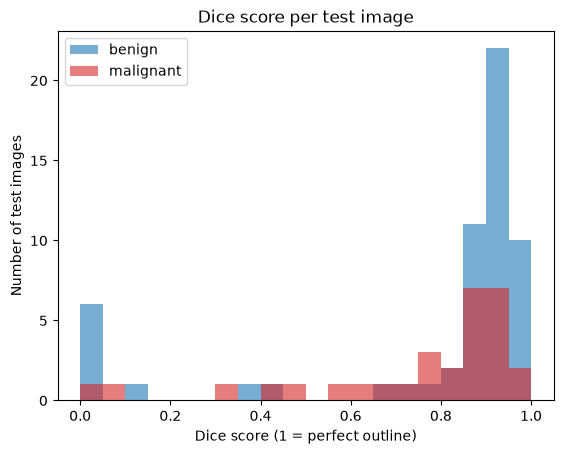

In [87]:
# Dice score of every tumour image, by class
for class_name, color in [('benign', 'tab:blue'), ('malignant', 'tab:red')]:
    plt.hist(results.loc[results['label'] == class_name, 'dice'], bins=20, range=(0, 1),
             alpha=0.6, color=color, label=class_name)
plt.xlabel('Dice score (1 = perfect outline)')
plt.ylabel('Number of test images')
plt.title('Dice score per test image')
plt.legend()
plt.savefig(OUTPUT_DIR / 'dice_distribution.png', dpi=120, bbox_inches='tight')
plt.show()

### Classification results (multi-task only)

The same numbers as `02_model_classifier`, so the two models can be compared directly. **v2:** v1 (most likely class) and v2 (tuned malignant threshold) side by side.

v1: most likely class
              precision    recall  f1-score   support

      normal      0.778     0.824     0.800        17
      benign      0.828     0.930     0.876        57
   malignant      0.955     0.700     0.808        30

    accuracy                          0.846       104
   macro avg      0.853     0.818     0.828       104
weighted avg      0.856     0.846     0.844       104

v2: malignant if P(malignant) >= 0.50
              precision    recall  f1-score   support

      normal      0.778     0.824     0.800        17
      benign      0.828     0.930     0.876        57
   malignant      0.955     0.700     0.808        30

    accuracy                          0.846       104
   macro avg      0.853     0.818     0.828       104
weighted avg      0.856     0.846     0.844       104



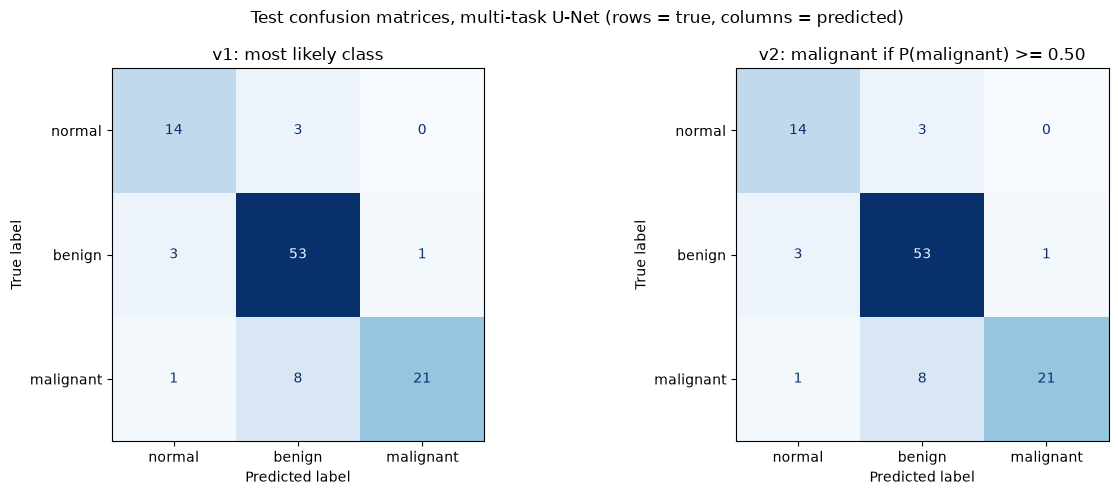

In [88]:
if MULTI_TASK:
    y_true = test_df['target'].values
    print('v1: most likely class')
    print(classification_report(y_true, y_pred_v1, target_names=CLASSES, digits=3))
    print(f'v2: malignant if P(malignant) >= {MALIGNANT_THRESHOLD:.2f}')
    print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3))

    # v2: v1 and v2 confusion matrices side by side
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for ax, (title, pred) in zip(axes, [('v1: most likely class', y_pred_v1),
                                        (f'v2: malignant if P(malignant) >= {MALIGNANT_THRESHOLD:.2f}', y_pred)]):
        ConfusionMatrixDisplay(confusion_matrix(y_true, pred), display_labels=CLASSES).plot(cmap='Blues', ax=ax, colorbar=False)
        ax.set_title(title)
    plt.suptitle('Test confusion matrices, multi-task U-Net (rows = true, columns = predicted)')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'confusion_matrix.png', dpi=120, bbox_inches='tight')
    plt.show()
else:
    print('MULTI_TASK is False: no classification head, skipping.')

### Shortcut check: images with vs without markers

If results are much better on images with markers, the model may be using the markers instead of the tissue.

In [89]:
marker_check = results[tumour].groupby('has_markers')['dice'].agg(dice='mean', images='count')
metrics['dice_with_markers'] = float(marker_check['dice'].get(True, float('nan')))
metrics['dice_without_markers'] = float(marker_check['dice'].get(False, float('nan')))

if MULTI_TASK:
    accuracy_check = results.groupby('has_markers')['correct'].mean()
    metrics['accuracy_with_markers'] = float(accuracy_check.get(True, float('nan')))
    metrics['accuracy_without_markers'] = float(accuracy_check.get(False, float('nan')))

# v2: the settings these results were produced with
metrics['malignant_threshold'] = MALIGNANT_THRESHOLD
metrics['normal_gate_threshold'] = NORMAL_GATE_THRESHOLD
metrics['smooth_masks'] = SMOOTH_MASKS
metrics['clean_masks'] = CLEAN_MASKS
metrics['test_images'] = int(len(results))

(OUTPUT_DIR / 'metrics.json').write_text(json.dumps(metrics, indent=2))     # save all test results (v2)
marker_check.round(3)

,dice,images
has_markers,,
False,0.846,30
True,0.730,57


## 8. See the predictions

**Green** = true lesion outline, **red** = predicted outline.

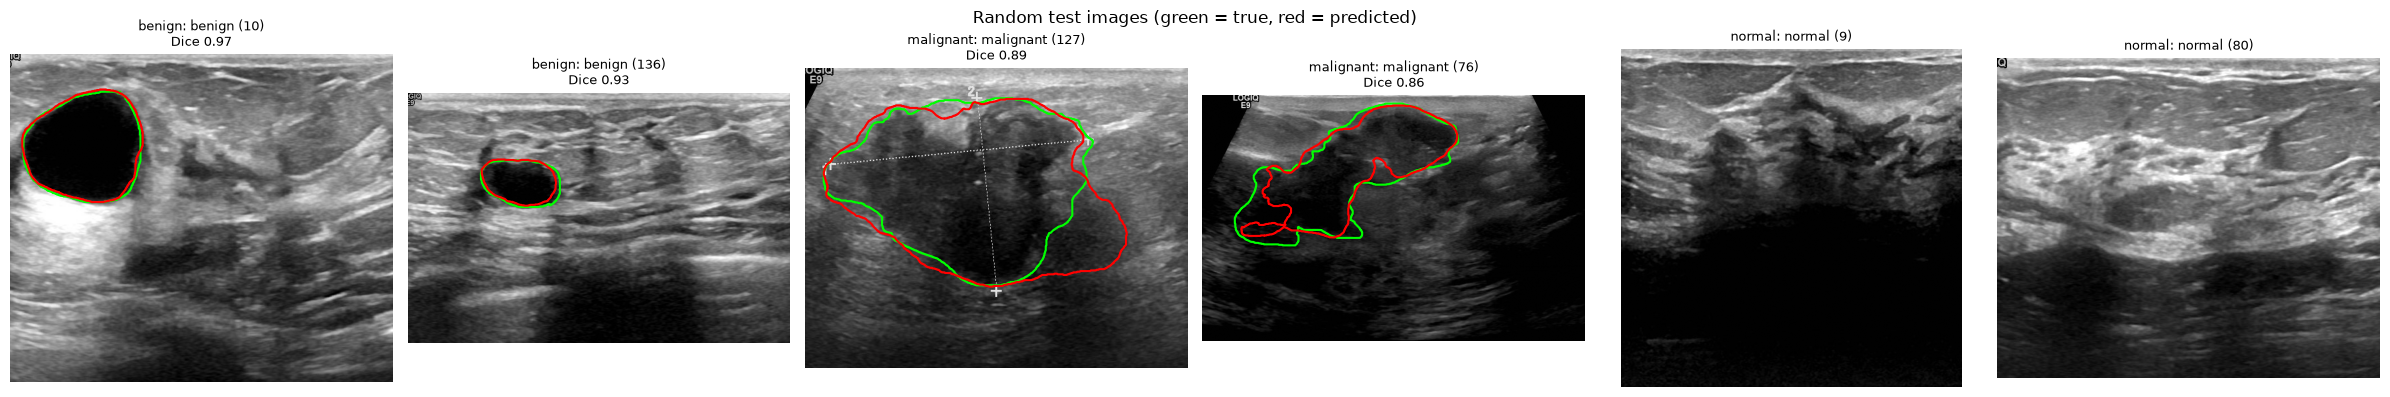

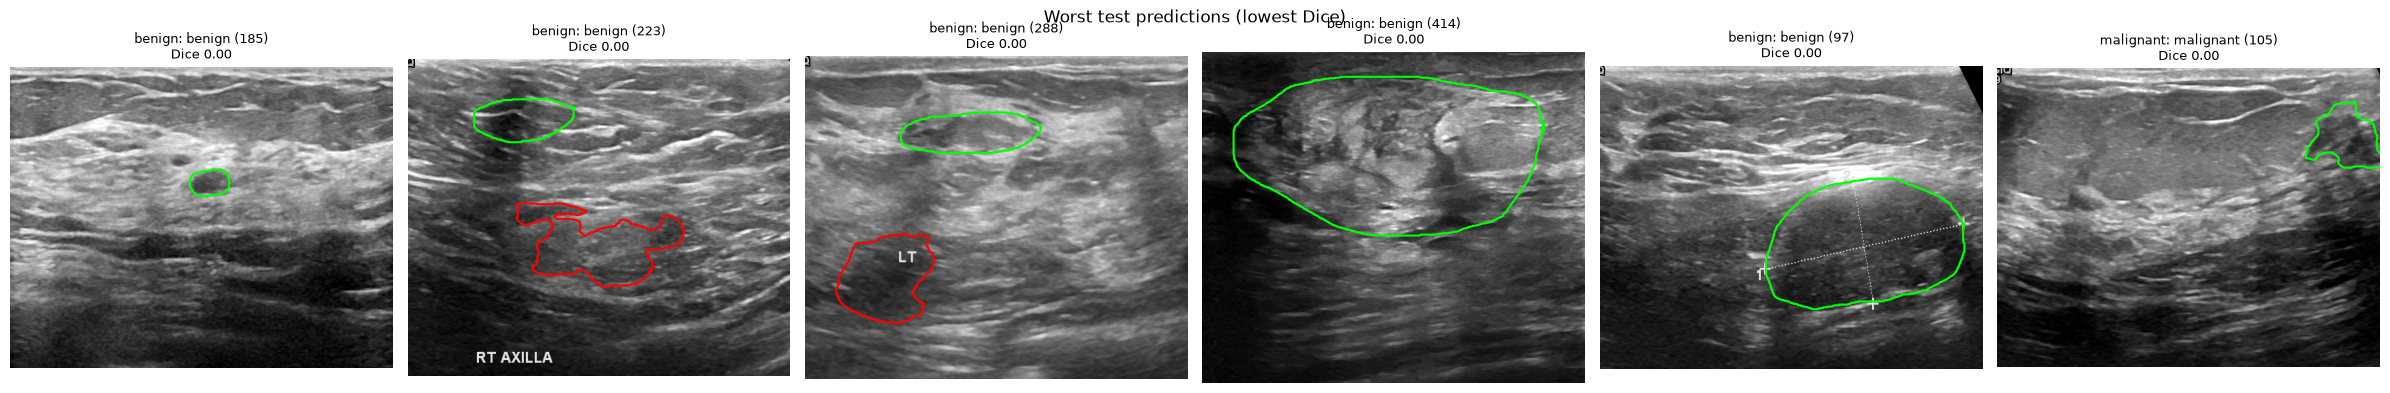

In [90]:
def show_predictions(rows, title, file_name):
    """Show test images with the true (green) and predicted (red) outlines, and save the figure."""
    fig, axes = plt.subplots(1, len(rows), figsize=(4 * len(rows), 4), squeeze=False)
    for ax, row in zip(axes[0], rows.itertuples()):
        image = Image.open(DATA_DIR / row.image_path).convert('L')
        truth = np.array(load_mask(test_df.loc[test_df['image_path'] == row.image_path, 'mask_paths'].iloc[0])) > 127
        pred = np.array(Image.open(OUTPUT_DIR / row.pred_mask_path)) > 127

        ax.imshow(image, cmap='gray')
        if truth.any():
            ax.contour(truth, levels=[0.5], colors='lime', linewidths=1.5)
        if pred.any():
            ax.contour(pred, levels=[0.5], colors='red', linewidths=1.5)

        name = f'{row.label}: {Path(row.image_path).stem}'
        ax.set_title(f'{name}\nDice {row.dice:.2f}' if row.label != 'normal' else name, fontsize=9)
        ax.axis('off')
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / file_name, dpi=120, bbox_inches='tight')
    plt.show()


examples = results.groupby('label', group_keys=False).sample(2, random_state=RANDOM_STATE)   # 2 per class
show_predictions(examples, 'Random test images (green = true, red = predicted)', 'prediction_examples.png')

worst = results[tumour].nsmallest(6, 'dice')                                             # hardest cases
show_predictions(worst, 'Worst test predictions (lowest Dice)', 'worst_predictions.png')

## 9. Save the config

The app needs to rebuild exactly the same model, preprocess uploaded images the same way and use the same threshold. Everything it needs is stored here.

In [91]:
config = {
    'model_name': 'U-Net (multi-task)' if MULTI_TASK else 'U-Net',
    'architecture': 'Unet',
    'encoder': ENCODER,
    'multi_task': MULTI_TASK,
    'classes': CLASSES,
    'image_size': IMAGE_SIZE,
    'preprocessing': 'grayscale -> pad to square with black -> resize -> 3 channels -> ImageNet normalisation',
    'normalize_mean': IMAGENET_MEAN,
    'normalize_std': IMAGENET_STD,
    'mask_threshold': MASK_THRESHOLD,
    'min_lesion_pixels': MIN_LESION_PIXELS,
    'smooth_masks': SMOOTH_MASKS,                        # v2: enlarge the probability map before thresholding
    'clean_masks': CLEAN_MASKS,                          # v2: mask cleanup settings
    'min_region_pct': MIN_REGION_PCT,
    'malignant_threshold': MALIGNANT_THRESHOLD,          # v2: tuned on the validation set
    'normal_gate_threshold': NORMAL_GATE_THRESHOLD,      # v2: None = off
    'decision_rule': 'malignant if P(malignant) >= malignant_threshold, else the more likely of normal / benign; '
                     'mask discarded if the class is normal and P(normal) >= normal_gate_threshold (if set)',
    'classification_dropout': 0.2,
    'class_loss_weight': CLASS_LOSS_WEIGHT,
    'best_epoch': int(best_epoch),
    'epochs_trained': int(len(history)),
    'batch_size': BATCH_SIZE,
    'learning_rate': LEARNING_RATE,
    'images': {'train': len(train_df), 'val': len(val_df), 'test': len(test_df)},
    'trained_on': datetime.now().strftime('%Y-%m-%d %H:%M') if TRAIN else previous_config['trained_on'],   # v2
    'evaluated_on': datetime.now().strftime('%Y-%m-%d %H:%M'),
}

(OUTPUT_DIR / 'config.json').write_text(json.dumps(config, indent=2))
print('Saved files:')
for path in sorted(OUTPUT_DIR.iterdir()):
    size = sum(f.stat().st_size for f in path.rglob('*')) if path.is_dir() else path.stat().st_size
    print(f'  {path.name:24s} {size / 1024:10.1f} KB')

Saved files:
  config.json                     1.1 KB
  confusion_matrix.png           42.9 KB
  dice_distribution.png          20.9 KB
  history.csv                     3.6 KB
  lesion_matches.csv              9.5 KB
  masks                         113.8 KB
  measurement_metrics.json        0.5 KB
  measurements.csv               16.7 KB
  metrics.json                    1.7 KB
  metrics_v1_vs_v2.csv            0.8 KB
  model.pt                    95612.5 KB
  overlays                    17536.7 KB
  prediction_examples.png       737.3 KB
  size_comparison.png            66.8 KB
  test_predictions.csv           21.2 KB
  threshold_tuning.png           64.0 KB
  training_curves.png           128.0 KB
  worst_predictions.png         803.7 KB


## 10. Check: reload and predict, the way the app will

This rebuilds the model from the saved files alone and predicts one test image. Its mask should match the one saved in `masks/` (Dice close to 1). If it works here, the app can use the same two functions.

In [92]:
def load_unet(folder):
    """Rebuild the trained U-Net from model.pt and config.json."""
    config = json.loads((folder / 'config.json').read_text())
    head = {'classes': len(config['classes']), 'dropout': config['classification_dropout']} if config['multi_task'] else None
    net = smp.Unet(encoder_name=config['encoder'], encoder_weights=None, in_channels=3, classes=1, aux_params=head)
    net.load_state_dict(torch.load(folder / 'model.pt', map_location='cpu'))
    net.eval()
    return net, config


def predict(net, config, image):
    """For one PIL image: lesion mask at the original size, plus class probabilities and predicted class if multi-task."""
    size = config['image_size']
    width, height = image.size
    padded = ImageOps.pad(image.convert('L'), (size, size), method=Image.BICUBIC, color=0)

    x = torch.from_numpy(np.array(padded)).float().div(255).unsqueeze(0).repeat(3, 1, 1)
    x = (x - torch.tensor(config['normalize_mean']).view(3, 1, 1)) / torch.tensor(config['normalize_std']).view(3, 1, 1)

    with torch.no_grad():
        output = net(x.unsqueeze(0))
    mask_logits, class_logits = output if config['multi_task'] else (output, None)

    lesion_probs = torch.sigmoid(mask_logits)[0, 0].numpy()
    if config.get('smooth_masks'):
        mask = unpad_probs(lesion_probs, width, height, size) > config['mask_threshold']   # v2: smooth edges
    else:
        mask = unpad_mask(lesion_probs > config['mask_threshold'], width, height, size)
    if config.get('clean_masks'):
        mask = clean_mask(mask, config['min_region_pct'], config['min_lesion_pixels'])      # v2: cleanup

    probabilities, predicted = None, None
    if class_logits is not None:
        p = torch.softmax(class_logits, dim=1)[0].numpy()
        # v2: malignant if P(malignant) >= the tuned threshold, otherwise the more likely of normal / benign
        index = 2 if p[2] >= config['malignant_threshold'] else int(p[:2].argmax())
        predicted = config['classes'][index]
        gate = config.get('normal_gate_threshold')
        if gate is not None and index == 0 and p[0] >= gate:
            mask = np.zeros_like(mask)                                                     # v2: normal gate
        probabilities = dict(zip(config['classes'], p.round(4).tolist()))
    return mask, probabilities, predicted


net, saved_config = load_unet(OUTPUT_DIR)
sample = results[tumour].iloc[0]
mask, probabilities, predicted = predict(net, saved_config, Image.open(DATA_DIR / sample['image_path']))
saved_mask = np.array(Image.open(OUTPUT_DIR / sample['pred_mask_path'])) > 127

print('Image:          ', sample['image_path'])
print('True label:     ', sample['label'])
print('Probabilities:  ', probabilities)
print('Predicted:      ', predicted)
print(f'Lesion pixels:   {mask.sum()}')
print(f'Match with saved mask (Dice): {dice_score(mask, saved_mask):.3f}  (should be close to 1)')

Image:           benign/benign (10).png
True label:      benign
Probabilities:   {'normal': 0.0, 'benign': 1.0, 'malignant': 0.0}
Predicted:       benign
Lesion pixels:   32782
Match with saved mask (Dice): 1.000  (should be close to 1)
